In [1]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import csv
from random import uniform
import time

# **PRACTICAL 1**


##*Data structure that indexes the data by user and by movie for all the dataset.*

In [ ]:
# @title
def create_index(file_path:str):
  import csv #importing the package to read csv file

  #Initialisation of indexing
  user_indexing = []
  movie_indexing = []

  user_index = {}
  movie_index = {}

  uindex = 0
  mindex = 0

  with open(file = file_path, mode='r', encoding='utf-8') as ratings:
    reader = csv.reader(ratings)
    next(reader) #dropping the header
    for rating in reader:

      if int(rating[0]) not in user_index.keys():
        user_index[int(rating[0])] = uindex
        user_indexing.append([int(rating[0])])
        uindex += 1

      if int(rating[1]) not in movie_index.keys():
        movie_index[int(rating[1])] = mindex
        movie_indexing.append([int(rating[1])])
        mindex += 1


      user_indexing[user_index[int(rating[0])]].append((int(rating[1]),float(rating[2])))
      movie_indexing[movie_index[int(rating[1])]].append((int(rating[0]),float(rating[2])))

    return user_indexing, movie_indexing

In [2]:
def create_train_test_data(file_path:str, total:int = int(1e-5), train_set_ratio:float = 0.9, split:bool = True, full:bool = False):

  #Initialisation of indexing

  data_by_user_train = []
  data_by_movie_train = []
  data_by_user_test = []
  data_by_movie_test = []

  user_index = {}
  movie_index = {}

  uindex = 0
  mindex = 0
  count = 0


  with open(file = file_path, mode='r', encoding='utf-8') as ratings:
    reader = csv.reader(ratings)
    next(reader) #dropping the header
    for rating in reader:
      count+=1

      if int(rating[0]) not in user_index.keys():
        user_index[int(rating[0])] = uindex
        data_by_user_train.append([int(rating[0])])
        if split:
          data_by_user_test.append([int(rating[0])])
        uindex += 1

      if int(rating[1]) not in movie_index.keys():
        movie_index[int(rating[1])] = mindex
        data_by_movie_train.append([int(rating[1])])
        if split:
          data_by_movie_test.append([int(rating[1])])
        mindex += 1

      if uniform(0.,1.) < train_set_ratio or not split:
        data_by_user_train[user_index[int(rating[0])]].append((int(rating[1]),float(rating[2])))
        data_by_movie_train[movie_index[int(rating[1])]].append((int(rating[0]),float(rating[2])))
      else:
        data_by_user_test[user_index[int(rating[0])]].append((int(rating[1]),float(rating[2])))
        data_by_movie_test[movie_index[int(rating[1])]].append((int(rating[0]),float(rating[2])))

      if not full and count == total:
        break


    if split:
      return data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index
    else:
      return data_by_user_train, data_by_movie_train, user_index, movie_index


In [3]:
user_indexing, movie_indexing, user_index, movie_index = create_train_test_data(file_path = "/content/drive/MyDrive/ml-32m/ratings.csv",split = False, full  = True)

##*Plot of rating distributions of data with the number of ratings (freedom degree) and it's frequency on a log-log scale.*

In [4]:
movie_ratings = [(len(rate)-1) for rate in movie_indexing]
user_ratings = [(len(rate)-1) for rate in user_indexing]

frequency_movies = Counter(movie_ratings)
frequency_users = Counter(user_ratings)

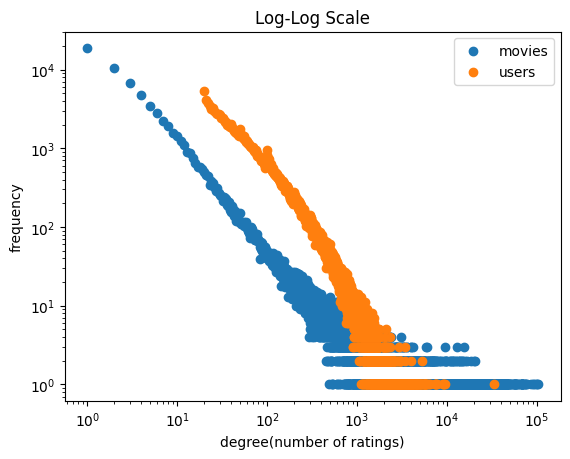

In [6]:
x_movies = list(frequency_movies.keys())
y_movies = list(frequency_movies.values())

x_users = list(frequency_users.keys())
y_users = list(frequency_users.values())

plt.scatter(x_movies, y_movies, label = "movies")
plt.scatter(x_users, y_users, label = "users")

plt.legend()

plt.xscale('log')
plt.yscale('log')

plt.ylabel("frequency")
plt.xlabel("degree(number of ratings)")

plt.title('Log-Log Scale')
plt.savefig("/content/drive/MyDrive/ml-32m/Plots/power_law.pdf", format="pdf", dpi=300)

plt.show()



###Interpretation of the log-log scale plot

The linearity of the log-log scale curve shows that there are power laws in the data.

The degree of freedom follows a power law from both users and movies point of view. The network is scale free.

In [7]:
user_indexing = []
movie_indexing = []
user_ratings = []
x_movies = []
x_users = []
y_movies = []
y_users = []
frequency_movies = Counter(movie_ratings)
frequency_users = Counter(user_ratings)
user_index = {}
movie_index = {}

# **DATA SPLITTING & MODEL TRAINING**

##*Split the data into training and test set using a normal probability distribution*

In [ ]:
# @title
def create_train_test_data(file_path:str, total:int, train_set_ratio:float):

  #Initialisation of indexing

  data_by_user_train = []
  data_by_movie_train = []
  data_by_user_test = []
  data_by_movie_test = []

  user_index = {}
  movie_index = {}

  uindex = 0
  mindex = 0


  with open(file = file_path, mode='r', encoding='utf-8') as ratings:
    reader = csv.reader(ratings)
    next(reader) #dropping the header
    for _ in range(total):
      rating = next(reader)

      if int(rating[0]) not in user_index.keys():
        user_index[int(rating[0])] = uindex
        data_by_user_train.append([int(rating[0])])
        data_by_user_test.append([int(rating[0])])
        uindex += 1

      if int(rating[1]) not in movie_index.keys():
        movie_index[int(rating[1])] = mindex
        data_by_movie_train.append([int(rating[1])])
        data_by_movie_test.append([int(rating[1])])
        mindex += 1

      if uniform(0.,1.) < train_set_ratio:
        data_by_user_train[user_index[int(rating[0])]].append((int(rating[1]),float(rating[2])))
        data_by_movie_train[movie_index[int(rating[1])]].append((int(rating[0]),float(rating[2])))
      else:
        data_by_user_test[user_index[int(rating[0])]].append((int(rating[1]),float(rating[2])))
        data_by_movie_test[movie_index[int(rating[1])]].append((int(rating[0]),float(rating[2])))


    return data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index


In [9]:
data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index = create_train_test_data(file_path = "/content/drive/MyDrive/ml-32m/ratings.csv", total = int(1e5), train_set_ratio=0.9,full = False)

In [10]:
movie_train = sum([(len(rate)-1) for rate in data_by_movie_train])
user_train = sum([(len(rate)-1) for rate in data_by_user_train])
movie_test = sum([(len(rate)-1) for rate in data_by_movie_test])
user_test = sum([(len(rate)-1) for rate in data_by_user_test])

print(f"Movie train: {movie_train}\nUser train: {user_train}\nMovie test: {movie_test}\nUser test: {user_test}\nMovie split ratio: {movie_train/(movie_train+movie_test) * 100}%\nUser split ratio: {user_train/(user_train+user_test)*100}%")

Movie train: 90041
User train: 90041
Movie test: 9959
User test: 9959
Movie split ratio: 90.04100000000001%
User split ratio: 90.04100000000001%


In [ ]:
# @title
def biases_only_training(data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index, n_iteration, Lambda, gamma):
  M = len(data_by_user_train)
  N = len(data_by_movie_train)

  Bm = [0] * M
  Bn = [0] * N

  train_loss = []
  test_loss = []
  train_rmse = []
  test_rmse = []

  for _ in range(n_iteration):
    for m in range(M):
      bm = 0
      item_counter = 0
      for pair in data_by_user_train[m][1:]:
        bm += Lambda * (pair[1] - Bn[movie_index[pair[0]]])
        item_counter += 1
      bm = bm / (Lambda * item_counter + gamma)
      Bm[m] = bm

    for n in range(N):
      bn = 0
      user_counter = 0
      for pair in data_by_movie_train[n][1:]:
        bn += Lambda * (pair[1] - Bm[user_index[pair[0]]])
        user_counter += 1
      bn = bn / (Lambda * user_counter + gamma)
      Bn[n] = bn

    train = compute_loss_and_rmse(data = data_by_user_train, n_elements = M, Lambda = Lambda, gamma = gamma, bias_users = Bm, bias_movies = Bn, movie_index = movie_index)
    train_loss.append(train[0])
    train_rmse.append(train[1])

    test = compute_loss_and_rmse(data = data_by_user_test, n_elements = M, Lambda = Lambda, gamma = gamma, bias_users = Bm, bias_movies = Bn, movie_index = movie_index)
    test_loss.append(test[0])
    test_rmse.append(test[1])

  return train_loss, test_loss, train_rmse, test_rmse

In [ ]:
# @title
def compute_loss_and_rmse(data, n_elements, Lambda, gamma, bias_users, bias_movies, movie_index ):
  loss = 0
  count = 0
  for element in range(n_elements):
      bias_user = bias_users[element]
      for pair in data[element][1:]:
        loss += (pair[1] - bias_movies[movie_index[pair[0]]] - bias_user)**2
        count += 1

  rmse = (loss/count)**(1/2)
  loss *= -Lambda/2
  user_bias_term = (-gamma/2) * sum([bm**2 for bm in bias_users])
  movie_bias_term = (-gamma/2) * sum([bn**2 for bn in bias_movies])
  loss += user_bias_term + movie_bias_term
  loss *= -1

  return loss,rmse



##*Functions to compute the loss, rmse, biases and trait vectors*

In [11]:
def compute_loss_and_rmse(data, index, Lambda, gamma, tau, Bm, Bn, U, V):
  loss = 0
  count = 0
  for m in range(len(data)):
      bm = Bm[m]
      for item, rmn in data[m][1:]:
        n = index[item]
        um = U[m]
        vn = V[n]
        bn = Bn[n]
        loss += (rmn - bn - bm - np.dot(um,vn))**2
        count += 1

  rmse = np.sqrt(loss/count)

  loss *= -Lambda/2

  user_bias_term = (-gamma/2) * np.dot(Bm,Bm)
  movie_bias_term = (-gamma/2) * np.dot(Bn,Bn)

  user_latent_term = (-tau/2) * np.sum(U**2)
  movie_latent_term = (-tau/2) * np.sum(V**2)

  loss += user_bias_term + movie_bias_term + user_latent_term + movie_latent_term
  loss *= -1

  return loss,rmse

In [ ]:
def compute_bias(data, index, B_prime, B, Lambda, gamma, L, L_prime):
  for m in range(len(data)):
      bm = 0
      item_counter = 0
      um = L[m]
      for item, rmn in data[m][1:]:
        n = index[item]
        vn = L_prime[n]
        bn = B_prime[n]
        bm += Lambda * (rmn - bn - np.dot(um,vn))
        item_counter += 1
      B[m] = bm / (Lambda * item_counter + gamma)
      #B[m] = bm

  return B


In [ ]:
def compute_latent_trait(data, index, L, L_prime, Lambda, tau, B, B_prime, K):
  for m in range(len(data)):
      bm = B[m]
      b = np.zeros((K,1))
      A = np.zeros((K,K))
      for item, rmn in data[m][1:]:
        n = index[item]
        vn = L_prime[n:n+1,:]
        bn = B_prime[n]
        b += Lambda * vn.T * (rmn - bm - bn)
        A += Lambda * np.dot(vn.T, vn)
      A += tau * np.identity(K)
      L[m] = np.transpose(np.linalg.solve(A,b))
      #L[m] = um.T

  return L


##*Function to train the model for every case*

In [14]:
def model_training(data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index, n_iteration, Lambda, gamma = 0., tau = 0., K = 1, bias = True, embedings = True):
  M = len(data_by_user_train)
  N = len(data_by_movie_train)

  Bm = np.zeros((M))
  Bn = np.zeros((N))

  U = np.random.normal(loc = 0.0, scale = np.sqrt(K), size = (M, K)) if embedings else np.zeros((M,K))
  V = np.random.normal(loc = 0.0, scale = np.sqrt(K), size = (N, K)) if embedings else np.zeros((N,K))

  train_loss = []
  test_loss = []
  train_rmse = []
  test_rmse = []

  for i in range(n_iteration):
    #User biases update
    start_time = time.perf_counter()
    if bias:
      Bm = compute_bias(data = data_by_user_train, index = movie_index, B_prime = Bn, B = Bm, Lambda = Lambda, gamma = gamma, L = U, L_prime = V)
      end_time = time.perf_counter()
      execution_time = end_time - start_time
      print(f"Operation took {execution_time:.6f} seconds to complete.")

    #User latent trait vectors update
    start_time = time.perf_counter()
    if embedings:
      U = compute_latent_trait(data = data_by_user_train, index = movie_index, L = U, L_prime = V, Lambda = Lambda, tau = tau, B = Bm, B_prime = Bn, K = K)
      end_time = time.perf_counter()
      execution_time = end_time - start_time
      print(f"Operation took {execution_time:.6f} seconds to complete.")

    #Movie biases update
    start_time = time.perf_counter()
    if bias:
      Bn = compute_bias(data = data_by_movie_train, index = user_index, B_prime = Bm, B = Bn, Lambda = Lambda, gamma = gamma, L = V, L_prime= U)
      end_time = time.perf_counter()
      execution_time = end_time - start_time
      print(f"Operation took {execution_time:.6f} seconds to complete.")

    #Movie latent trait vectors update
    start_time = time.perf_counter()
    if embedings:
      V = compute_latent_trait(data = data_by_movie_train, index = user_index, L = V, L_prime = U, Lambda = Lambda, tau = tau, B = Bn, B_prime = Bm, K = K)
      end_time = time.perf_counter()
      execution_time = end_time - start_time
      print(f"Operation took {execution_time:.6f} seconds to complete.")

    start_time = time.perf_counter()
    loss, rmse = compute_loss_and_rmse(data = data_by_user_train, index = movie_index, Lambda = Lambda, gamma = gamma, tau = tau, Bm = Bm, Bn = Bn, U = U, V = V)
    end_time = time.perf_counter()
    execution_time = end_time - start_time
    print(f"Operation took {execution_time:.6f} seconds to complete.")
    print(f"################################## Iteration {i+1} ###############################\nTrain loss : {loss}\nTrain rmse : {rmse}\n")
    train_loss.append(loss)
    train_rmse.append(rmse)

    start_time = time.perf_counter()
    loss, rmse = compute_loss_and_rmse(data = data_by_user_test, index = movie_index, Lambda = Lambda, gamma = gamma, tau = tau, Bm = Bm, Bn = Bn, U = U, V = V)
    end_time = time.perf_counter()
    execution_time = end_time - start_time
    print(f"Operation took {execution_time:.6f} seconds to complete.")
    print(f"Test loss : {loss}\nTest rmse : {rmse}\n###########################################################################\n")
    test_loss.append(loss)
    test_rmse.append(rmse)

  if bias and embedings:
    return U,V,Bm,Bn,train_loss, test_loss, train_rmse, test_rmse
  elif bias:
    return Bm,Bn,train_loss, test_loss, train_rmse, test_rmse
  elif embedings:
    return U,V,train_loss, test_loss, train_rmse, test_rmse

## *Function to plot the loss and RMSE curves*

In [15]:
def plot_loss_and_rmse(train_loss, test_loss, train_rmse, test_rmse, model = ""):
  fig, axs = plt.subplots(nrows = 1,ncols = 2, figsize = (15,5))
  axs[0].plot(train_loss, label = "Train")
  axs[0].plot(test_loss, label = "Test")


  axs[0].set(xlabel = "Number of iterations",ylabel = "Loss")

  axs[0].set_title('Train and Test Loss')



  axs[1].plot(train_rmse, label = "Train")
  axs[1].plot(test_rmse, label = "Test")



  axs[1].set(xlabel = "Number of iterations",ylabel = "RMSE")

  axs[1].set_title('Train and Test RMSE')


  fig.suptitle("Loss and RMSE for "+ model)

  plt.savefig("/content/drive/MyDrive/ml-32m/Plots/"+model+".pdf", format="pdf", dpi=300)


  plt.show()

# **MODEL WITHOUT BIASES**

Operation took 0.190003 seconds to complete.
Operation took 0.786487 seconds to complete.
Operation took 0.212598 seconds to complete.
################################## Iteration 1 ###############################
Train loss : 5742.207124864139
Train rmse : 3.4722438553730104

Operation took 0.043321 seconds to complete.
Test loss : 934.4078086298954
Test rmse : 3.5288522533432727
###########################################################################

Operation took 0.180065 seconds to complete.
Operation took 0.652595 seconds to complete.
Operation took 0.210116 seconds to complete.
################################## Iteration 2 ###############################
Train loss : 1320.6369094335623
Train rmse : 1.100909248127005

Operation took 0.043815 seconds to complete.
Test loss : 891.832683201004
Test rmse : 1.5318341780531488
###########################################################################

Operation took 0.180289 seconds to complete.
Operation took 0.653859 seconds to

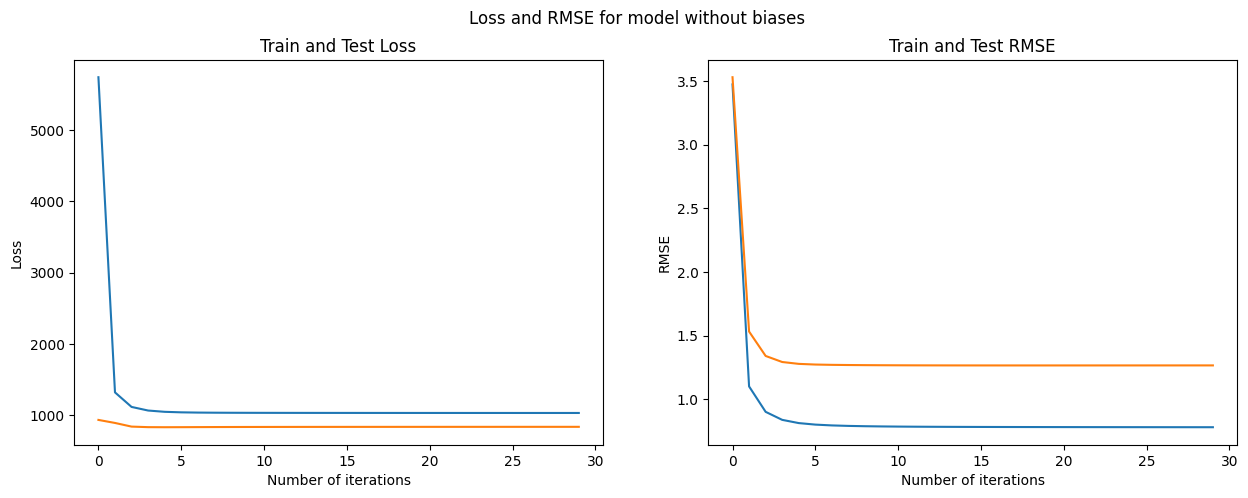

In [17]:
U,V,train_loss_latent, test_loss_latent, train_rmse_latent, test_rmse_latent = model_training(data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index, n_iteration = 30, Lambda = 0.01, tau=0.13, K = 20, bias= False)

plot_loss_and_rmse(train_loss_latent, test_loss_latent, train_rmse_latent, test_rmse_latent, model = "model without biases")

# **PRACTICAL 2**
## *Model with biases only*

Operation took 0.052911 seconds to complete.
Operation took 0.207416 seconds to complete.
Operation took 0.215837 seconds to complete.
################################## Iteration 1 ###############################
Train loss : 367.91463838173905
Train rmse : 0.8356574073653676

Operation took 0.041707 seconds to complete.
Test loss : 95.37008138830484
Test rmse : 0.9166935414486146
###########################################################################

Operation took 0.073685 seconds to complete.
Operation took 0.227727 seconds to complete.
Operation took 0.191090 seconds to complete.
################################## Iteration 2 ###############################
Train loss : 358.8403728206877
Train rmse : 0.8243752361670443

Operation took 0.048324 seconds to complete.
Test loss : 93.84104791410431
Test rmse : 0.9069305120020761
###########################################################################

Operation took 0.074986 seconds to complete.
Operation took 0.242718 seconds 

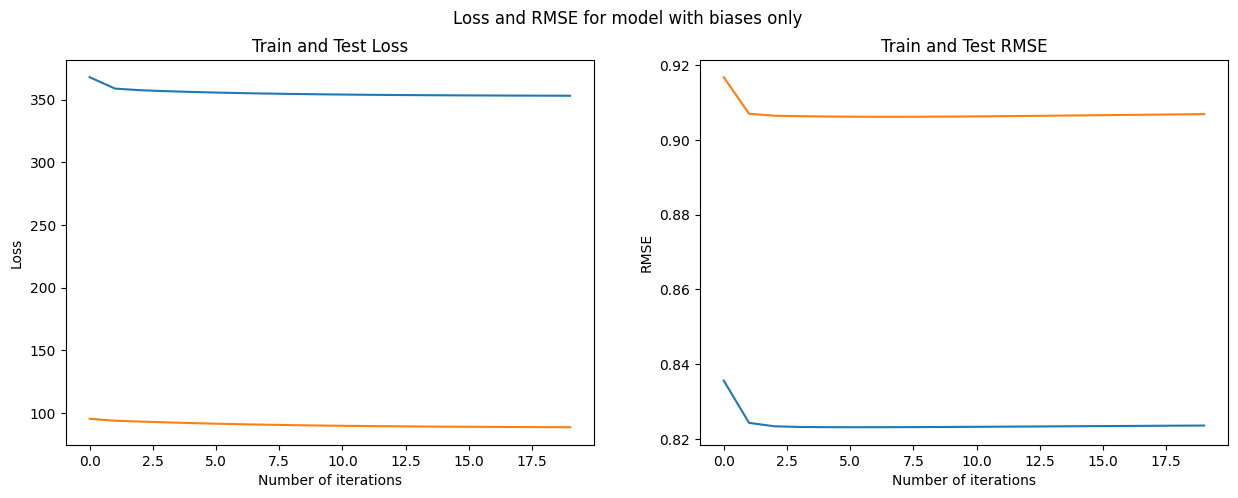

In [16]:
Bm,Bn,train_loss_biases, test_loss_biases, train_rmse_biases, test_rmse_biases = model_training(data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index, n_iteration = 20, Lambda = 0.01 , gamma = 0.01,embedings = False)

plot_loss_and_rmse(train_loss_biases, test_loss_biases, train_rmse_biases, test_rmse_biases, model = "model with biases only")


# **PRACTICAL 3**
## *Model with biases and embedings*

Operation took 0.063105 seconds to complete.
Operation took 0.180601 seconds to complete.
Operation took 0.224608 seconds to complete.
Operation took 0.637233 seconds to complete.
Operation took 0.199373 seconds to complete.
################################## Iteration 1 ###############################
Train loss : 13246.702831214272
Train rmse : 4.518255151012918

Operation took 0.048039 seconds to complete.
Test loss : 6180.093211335732
Test rmse : 6.531314734921656
###########################################################################

Operation took 0.090466 seconds to complete.
Operation took 0.177335 seconds to complete.
Operation took 0.247664 seconds to complete.
Operation took 0.617380 seconds to complete.
Operation took 0.206346 seconds to complete.
################################## Iteration 2 ###############################
Train loss : 2693.2367770253345
Train rmse : 1.5488807664712012

Operation took 0.043263 seconds to complete.
Test loss : 2138.792735179981
Test r

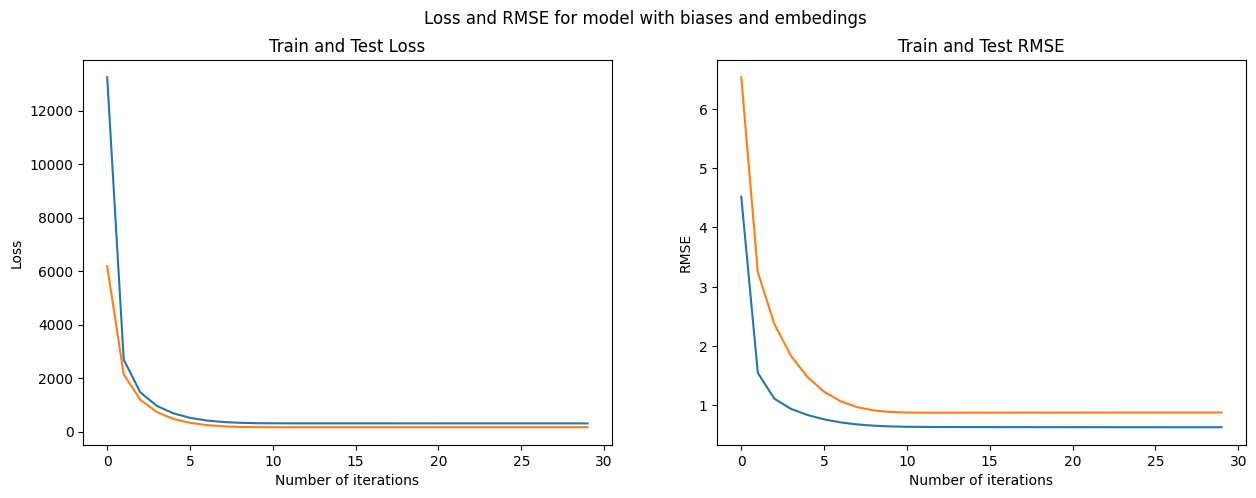

In [19]:
U,V,Bm,Bn,train_loss_full, test_loss_full, train_rmse_full, test_rmse_full = model_training(data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index, n_iteration = 30, Lambda = 0.01 , gamma = 0.01, tau=0.13, K = 20)

plot_loss_and_rmse(train_loss_full, test_loss_full, train_rmse_full, test_rmse_full, model = "model with biases and embedings")

In [20]:
data_by_movie_train = []
data_by_user_train = []

#**PRACTICAL 4**

## *Hyperparameters tuning*

## *Optimization*

Code my cholesky decomposition (solver).

Code my matrix multiplication for the outer product of a vector with itself.

Using of Numba.

Find a way to subseting a matrix Vn instead of looping over n for latents trait vectors updates.

In [ ]:
# @title
def cholesky_decomposition():

In [ ]:
# @title
def cholesky_solver(A,b):

In [13]:
def compute_bias(data, index, B_prime, B, Lambda, gamma, L, L_prime):
  for m in range(len(data)):
      bm = 0
      #item_counter = 0
      um = L[m]
      n = [index[item[0]] for item in data[m][1:]]
      rmn = np.array([item[1] for item in data[m][1:]])
      #for item, rmn in data[m][1:]:
        #n = index[item]
        #vn = L_prime[n]
        #bn = B_prime[n]
      bm = Lambda * (rmn - B_prime[n] - np.dot(um,L_prime[n].T))
        #item_counter += 1
      B[m] = np.sum(bm) / (Lambda * len(n) + gamma)
      #B[m] = bm

  return B


In [12]:
def compute_latent_trait(data, index, L, L_prime, Lambda, tau, B, B_prime, K):
  for m in range(len(data)):
    bm = B[m]
      #for item, rmn in data[m][1:]:
    n = [index[item[0]] for item in data[m][1:]]
    rmn = np.array([item[1] for item in data[m][1:]])
        #vn = L_prime[n:n+1,:]
        #bn = B_prime[n]
        #b += Lambda * vn.T * (rmn - bm - bn)
        #A += Lambda * np.dot(vn.T, vn)
    b = Lambda * L_prime[n].T@(rmn - bm - B_prime[n]).T
    A = Lambda * np.dot(L_prime[n].T, L_prime[n]) + tau * np.identity(K)
    L[m] = np.transpose(np.linalg.solve(A,b))
      #L[m] = um.T

  return L

In [24]:
data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index = create_train_test_data(file_path = "/content/drive/MyDrive/ml-32m/ratings.csv", total = int(1e5), train_set_ratio=0.999,full = True)

In [25]:
movie_train = sum([(len(rate)-1) for rate in data_by_movie_train])
user_train = sum([(len(rate)-1) for rate in data_by_user_train])
movie_test = sum([(len(rate)-1) for rate in data_by_movie_test])
user_test = sum([(len(rate)-1) for rate in data_by_user_test])

print(f"Movie train: {movie_train}\nUser train: {user_train}\nMovie test: {movie_test}\nUser test: {user_test}\nMovie split ratio: {movie_train/(movie_train+movie_test) * 100}%\nUser split ratio: {user_train/(user_train+user_test)*100}%")

Movie train: 31968451
User train: 31968451
Movie test: 31753
User test: 31753
Movie split ratio: 99.90077250757527%
User split ratio: 99.90077250757527%


Operation took 23.722133 seconds to complete.
Operation took 76.277067 seconds to complete.
Operation took 72.495635 seconds to complete.
Operation took 144.217733 seconds to complete.
Operation took 90.435331 seconds to complete.
################################## Iteration 1 ###############################
Train loss : 3351674.7266783533
Train rmse : 4.30579588783378

Operation took 0.390361 seconds to complete.
Test loss : 394569.13990762254
Test rmse : 6.324434102373433
###########################################################################

Operation took 22.679276 seconds to complete.
Operation took 76.585235 seconds to complete.
Operation took 70.998016 seconds to complete.
Operation took 144.346206 seconds to complete.
Operation took 87.550079 seconds to complete.
################################## Iteration 2 ###############################
Train loss : 322356.161628149
Train rmse : 0.9163329029099647

Operation took 0.237250 seconds to complete.
Test loss : 188350.7590374

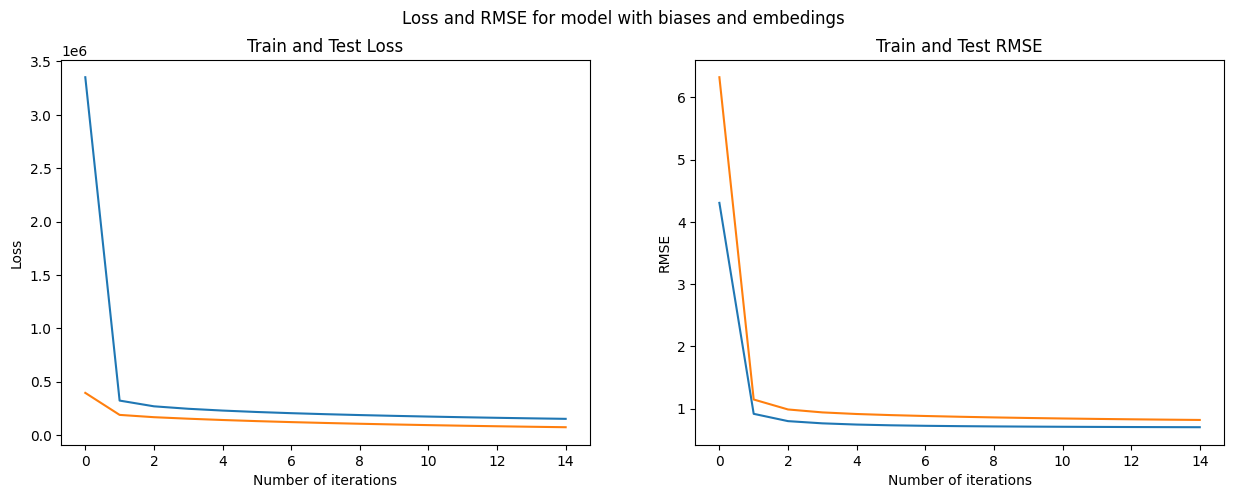

In [27]:
U,V,Bm,Bn,train_loss_full, test_loss_full, train_rmse_full, test_rmse_full = model_training(data_by_user_train, data_by_movie_train, data_by_user_test, data_by_movie_test, user_index, movie_index, n_iteration = 15, Lambda = 0.01 , gamma = 0.01, tau=0.13, K = 20)

plot_loss_and_rmse(train_loss_full, test_loss_full, train_rmse_full, test_rmse_full, model = "model with biases and embedings")

In [31]:
data_by_movie_train = []
data_by_user_train = []
data_by_movie_test = []
data_by_user_test = []

## *Function to do inference*

In [32]:
def map_movie_name(file_path:str, index):

  #Initialisation of indexing
  movie_name_indexing = [""]*len(index)
  with open(file = file_path, mode='r', encoding='utf-8') as names:
    reader = csv.reader(names)
    next(reader) #dropping the header
    for name in reader:
      if int(name[0]) in index.keys():
        movie_name_indexing[index[int(name[0])]] = name[1]
      #movie_name_indexing[index[int(name[0])]] = name[1]

  return movie_name_indexing

In [41]:
movie_name = map_movie_name(file_path = "/content/drive/MyDrive/ml-32m/movies.csv", index = movie_index)

In [33]:
def inference(data, index, L_prime, Lambda, tau, B, B_prime, K, movie_ratings, movie_name_indexing, regularisation_factor  = 1., min_ratings = 20):
  L = [0]
  scores = []
  u = compute_latent_trait(data, index, L, L_prime, Lambda, tau, B, B_prime, K)[0]
  for n in range(len(B_prime)):
    if movie_ratings[n] < min_ratings:
      scores.append((-10.,movie_name_indexing[n]))
    else:
      scores.append(((np.dot(u,L_prime[n]) + regularisation_factor*B_prime[n]),movie_name_indexing[n]))
  return sorted(scores, reverse = True)

In [49]:
def show_recommendations(recommendations, movie_name, data, index):
  print(f"You give the movie: {movie_name[index[data[0][1][0]]]} a score of {data[0][1][1]} \n\nOur recommendations are:\n")
  print('='*25)
  for recommendation in recommendations:
    print(recommendation[1]+"\n")
    print('='*25)

# **Test for Dummy Users**

## *User1*

In [52]:
data1 = [[0,(89745,5.)]]

In [53]:
recommendations = inference(data = data1 , index = movie_index, L_prime = V, Lambda = .01, tau = .13, B = [0], B_prime = Bn, K = 20, movie_ratings = movie_ratings, movie_name_indexing = movie_name)
show_recommendations(recommendations[:10], movie_name = movie_name, data = data1, index = movie_index)

You give the movie: Avengers, The (2012) a score of 5.0 

Our recommendations are:

Avengers: Infinity War - Part I (2018)

Avengers, The (2012)

Avengers: Infinity War - Part II (2019)

Guardians of the Galaxy (2014)

Usual Suspects, The (1995)

Star Wars: Episode IV - A New Hope (1977)

Iron Man (2008)

Dark Knight, The (2008)

Shawshank Redemption, The (1994)

Lord of the Rings: The Fellowship of the Ring, The (2001)



In [54]:
recommendations = inference(data = data1 , index = movie_index, L_prime = V, Lambda = .01, tau = .13, B = [0], B_prime = Bn, K = 20, movie_ratings = movie_ratings, movie_name_indexing = movie_name, regularisation_factor  = .05)
show_recommendations(recommendations[:10], movie_name = movie_name, data = data1, index = movie_index)

You give the movie: Avengers, The (2012) a score of 5.0 

Our recommendations are:

Avengers, The (2012)

Avengers: Infinity War - Part I (2018)

Avengers: Infinity War - Part II (2019)

Guardians of the Galaxy (2014)

Iron Man (2008)

Thor: Ragnarok (2017)

Captain America: The Winter Soldier (2014)

Captain America: Civil War (2016)

Deadpool (2016)

Avengers: Age of Ultron (2015)



In [56]:
recommendations = inference(data = data1 , index = movie_index, L_prime = V, Lambda = .01, tau = .13, B = [0], B_prime = Bn, K = 20, movie_ratings = movie_ratings, movie_name_indexing = movie_name, regularisation_factor  = .05, min_ratings = 100)
show_recommendations(recommendations[:10], movie_name = movie_name, data = data1, index = movie_index)

You give the movie: Avengers, The (2012) a score of 5.0 

Our recommendations are:

Avengers, The (2012)

Avengers: Infinity War - Part I (2018)

Avengers: Infinity War - Part II (2019)

Guardians of the Galaxy (2014)

Iron Man (2008)

Thor: Ragnarok (2017)

Captain America: The Winter Soldier (2014)

Captain America: Civil War (2016)

Deadpool (2016)

Avengers: Age of Ultron (2015)



## *User2*

In [63]:
data2 = [[0,(8368,5.)]]

In [64]:
recommendations = inference(data = data2 , index = movie_index, L_prime = V, Lambda = .01, tau = .13, B = [0], B_prime = Bn, K = 20, movie_ratings = movie_ratings, movie_name_indexing = movie_name)
show_recommendations(recommendations[:10], movie_name = movie_name, data = data2, index = movie_index)

You give the movie: Harry Potter and the Prisoner of Azkaban (2004) a score of 5.0 

Our recommendations are:

Harry Potter and the Prisoner of Azkaban (2004)

Harry Potter and the Deathly Hallows: Part 2 (2011)

Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)

Harry Potter and the Goblet of Fire (2005)

Harry Potter and the Half-Blood Prince (2009)

Harry Potter and the Deathly Hallows: Part 1 (2010)

Harry Potter and the Chamber of Secrets (2002)

Harry Potter and the Order of the Phoenix (2007)

Lord of the Rings: The Return of the King, The (2003)

Lord of the Rings: The Fellowship of the Ring, The (2001)



In [65]:
recommendations = inference(data = data2 , index = movie_index, L_prime = V, Lambda = .01, tau = .13, B = [0], B_prime = Bn, K = 20, movie_ratings = movie_ratings, movie_name_indexing = movie_name, regularisation_factor  = .05)
show_recommendations(recommendations[:10], movie_name = movie_name, data = data2, index = movie_index)

You give the movie: Harry Potter and the Prisoner of Azkaban (2004) a score of 5.0 

Our recommendations are:

Harry Potter and the Prisoner of Azkaban (2004)

Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)

Harry Potter and the Chamber of Secrets (2002)

Harry Potter and the Goblet of Fire (2005)

Harry Potter and the Half-Blood Prince (2009)

Harry Potter and the Deathly Hallows: Part 2 (2011)

Harry Potter and the Deathly Hallows: Part 1 (2010)

Harry Potter and the Order of the Phoenix (2007)

Lord of the Rings: The Return of the King, The (2003)

Lord of the Rings: The Two Towers, The (2002)



In [66]:
recommendations = inference(data = data2 , index = movie_index, L_prime = V, Lambda = .01, tau = .13, B = [0], B_prime = Bn, K = 20, movie_ratings = movie_ratings, movie_name_indexing = movie_name, regularisation_factor  = .05, min_ratings = 100)
show_recommendations(recommendations[:10], movie_name = movie_name, data = data2, index = movie_index)

You give the movie: Harry Potter and the Prisoner of Azkaban (2004) a score of 5.0 

Our recommendations are:

Harry Potter and the Prisoner of Azkaban (2004)

Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)

Harry Potter and the Chamber of Secrets (2002)

Harry Potter and the Goblet of Fire (2005)

Harry Potter and the Half-Blood Prince (2009)

Harry Potter and the Deathly Hallows: Part 2 (2011)

Harry Potter and the Deathly Hallows: Part 1 (2010)

Harry Potter and the Order of the Phoenix (2007)

Lord of the Rings: The Return of the King, The (2003)

Lord of the Rings: The Two Towers, The (2002)



## *Polarizing movies*